In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

In [2]:
pd.options.display.max_columns = 1000
sns.set_theme(palette="dark", style="darkgrid")

df = pd.read_csv("steam_games.csv")
df.columns

Index(['steam_appid', 'name', 'developers', 'publishers', 'categories',
       'genres', 'required_age', 'n_achievements', 'platforms', 'is_released',
       'release_date', 'additional_content', 'total_reviews', 'total_positive',
       'total_negative', 'review_score', 'review_score_desc',
       'positive_percentual', 'metacritic', 'is_free', 'price_initial (USD)'],
      dtype='str')

In [3]:
df["positive_percentual"].value_counts()

positive_percentual
0.0      29562
100.0    10844
50.0      2286
66.7      1476
75.0      1053
         ...  
26.8         1
54.6         1
32.9         1
99.6         1
66.6         1
Name: count, Length: 805, dtype: int64

In [4]:
df = df.drop(columns=["additional_content"])
df.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD)
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"['Single-player', 'Family Sharing']","['Casual', 'Indie']",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"['Single-player', 'Multi-player', 'Co-op', 'On...","['Action', 'Adventure']",0,0,['windows'],False,Not Released,0,0,0,0.0,No user reviews,0.0,0,False,0.00
2,2719600,Lorhaven: Cursed War,['GoldenGod Games'],['GoldenGod Games'],"['Single-player', 'Multi-player', 'PvP', 'Shar...","['RPG', 'Strategy']",0,32,"['windows', 'mac']",True,2024-01-26,9,8,1,0.0,9 user reviews,88.9,0,False,9.99
3,2719610,PUIQ: Demons,['Giammnn'],['Giammnn'],"['Single-player', 'Steam Achievements', 'Famil...","['Action', 'Casual', 'Indie', 'RPG']",0,28,['windows'],True,2024-02-17,0,0,0,0.0,No user reviews,0.0,0,False,2.99
4,2719650,Project XSTING,['Saucy Melon'],['Saucy Melon'],"['Single-player', 'Steam Achievements', 'Steam...","['Action', 'Casual', 'Indie', 'Early Access']",0,42,['windows'],True,2024-01-05,9,9,0,0.0,9 user reviews,100.0,0,False,7.99


In [5]:
df["release_date"].unique()

<StringArray>
[         '2024-01-04',        'Not Released',          '2024-01-26',
          '2024-02-17',          '2024-01-05',          '2024-01-15',
          '2024-03-26',          '2024-02-29',          '2024-05-23',
          '2024-06-08',
 ...
 '2017-07-09 00:00:00', '2022-07-06 00:00:00', '2017-12-30 00:00:00',
 '2017-12-02 00:00:00', '2016-11-26 00:00:00', '2016-09-04 00:00:00',
 '2020-04-27 00:00:00', '2019-12-01 00:00:00', '2020-06-27 00:00:00',
 '2020-08-09 00:00:00']
Length: 4346, dtype: str

In [6]:
df["release_date"] = df["release_date"].astype(str).str.split(" ").str[0]

In [7]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD)
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"['Single-player', 'Family Sharing']","['Casual', 'Indie']",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"['Single-player', 'Multi-player', 'Co-op', 'On...","['Action', 'Adventure']",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00
2,2719600,Lorhaven: Cursed War,['GoldenGod Games'],['GoldenGod Games'],"['Single-player', 'Multi-player', 'PvP', 'Shar...","['RPG', 'Strategy']",0,32,"['windows', 'mac']",True,2024-01-26,9,8,1,0.0,9 user reviews,88.9,0,False,9.99
3,2719610,PUIQ: Demons,['Giammnn'],['Giammnn'],"['Single-player', 'Steam Achievements', 'Famil...","['Action', 'Casual', 'Indie', 'RPG']",0,28,['windows'],True,2024-02-17,0,0,0,0.0,No user reviews,0.0,0,False,2.99
4,2719650,Project XSTING,['Saucy Melon'],['Saucy Melon'],"['Single-player', 'Steam Achievements', 'Steam...","['Action', 'Casual', 'Indie', 'Early Access']",0,42,['windows'],True,2024-01-05,9,9,0,0.0,9 user reviews,100.0,0,False,7.99


In [8]:
df["release_year"]  = df["release_date"].dt.year.astype("Int32")
df["release_month"] = df["release_date"].dt.month.astype("Int32")
df["release_day"]   = df["release_date"].dt.day.astype("Int32")
df.drop(columns=["release_date"])

df.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD),release_year,release_month,release_day
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"['Single-player', 'Family Sharing']","['Casual', 'Indie']",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"['Single-player', 'Multi-player', 'Co-op', 'On...","['Action', 'Adventure']",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
2,2719600,Lorhaven: Cursed War,['GoldenGod Games'],['GoldenGod Games'],"['Single-player', 'Multi-player', 'PvP', 'Shar...","['RPG', 'Strategy']",0,32,"['windows', 'mac']",True,2024-01-26,9,8,1,0.0,9 user reviews,88.9,0,False,9.99,2024,1,26
3,2719610,PUIQ: Demons,['Giammnn'],['Giammnn'],"['Single-player', 'Steam Achievements', 'Famil...","['Action', 'Casual', 'Indie', 'RPG']",0,28,['windows'],True,2024-02-17,0,0,0,0.0,No user reviews,0.0,0,False,2.99,2024,2,17
4,2719650,Project XSTING,['Saucy Melon'],['Saucy Melon'],"['Single-player', 'Steam Achievements', 'Steam...","['Action', 'Casual', 'Indie', 'Early Access']",0,42,['windows'],True,2024-01-05,9,9,0,0.0,9 user reviews,100.0,0,False,7.99,2024,1,5


In [9]:
df["release_year"].value_counts()

release_year
2024    9693
2023    7903
2021    7627
2019    6082
2020    5093
2022    4768
2017    4355
2018    4178
2016    3400
2015    2157
2014    1201
2025     592
2013     305
2012     200
2011     162
2009     145
2010     133
2008      28
2007       7
2006       5
2005       3
2001       2
1997       1
2003       1
Name: count, dtype: Int64

In [10]:
df["is_released"].value_counts()

is_released
True     58041
False    13388
Name: count, dtype: int64

In [11]:
df["release_date"].notnull().value_counts()

release_date
True     58041
False    13388
Name: count, dtype: int64

In [12]:
df["categories"].dtype

<StringDtype(storage='python', na_value=nan)>

In [13]:
df["categories"] = df["categories"].replace("[]", pd.NA)
df["categories"] = df["categories"].dropna().astype(str).str[1:-1].str.replace("'", "").str.split(", ")

categories_exploded = df.explode("categories").dropna(subset=["categories"])
categories_exploded.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD),release_year,release_month,release_day
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],Single-player,"['Casual', 'Indie']",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],Family Sharing,"['Casual', 'Indie']",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],Single-player,"['Action', 'Adventure']",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],Multi-player,"['Action', 'Adventure']",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],Co-op,"['Action', 'Adventure']",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>


In [14]:
categories_exploded["categories"].unique()

<StringArray>
[             'Single-player',             'Family Sharing',
               'Multi-player',                      'Co-op',
               'Online Co-op',                        'PvP',
    'Shared/Split Screen PvP',  'Shared/Split Screen Co-op',
        'Shared/Split Screen',         'Steam Achievements',
      'Includes level editor',       'Remote Play Together',
                'Steam Cloud',    'Full controller support',
                      'Stats',              'HDR available',
 'Tracked Controller Support',                    'VR Only',
                 'Online PvP', 'Partial Controller Support',
                        'MMO', 'Cross-Platform Multiplayer',
           'In-App Purchases',         'Steam Leaderboards',
             'Steam Workshop',                  'LAN Co-op',
          'Remote Play on TV',         'Captions available',
                    'LAN PvP',        'Steam Trading Cards',
               'VR Supported',       'Commentary available',
       'Re

Text(0.5, 1.0, 'Number of Games with Single-player, Multi-player, and Co-op')

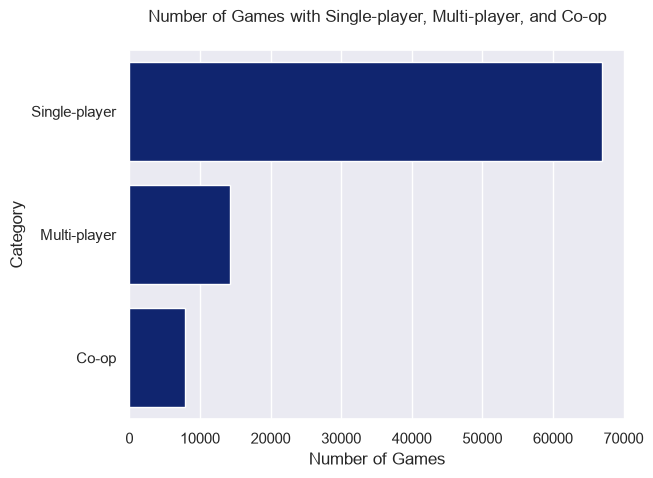

In [15]:
category_counts = categories_exploded["categories"].where( 
    (categories_exploded["categories"] == "Single-player") |
    (categories_exploded["categories"] == "Multi-player") |
    (categories_exploded["categories"] == "Co-op"))\
    .value_counts().reset_index()
    
category_counts.columns = ["Category", "Number of Games"]

sns.barplot(category_counts, x="Number of Games", y="Category")
plt.title("Number of Games with Single-player, Multi-player, and Co-op", pad=20)

In [16]:
filter = categories_exploded[categories_exploded["categories"].isin(["Single-player", "Multi-player", "Co-op"])].copy()

category_counts_year = filter[["categories", "release_year", "steam_appid"]]\
    .groupby(["categories", "release_year"]).count().reset_index()

category_counts_year.columns = ["Category", "Release Year", "# of Games"]
category_counts_year = category_counts_year[(category_counts_year["Release Year"] > 2010) & (category_counts_year["Release Year"] != 2025)]

category_counts_year

,Category,Release Year,# of Games
4,Co-op,2011,27
5,Co-op,2012,39
6,Co-op,2013,52
7,Co-op,2014,99
8,Co-op,2015,193
9,Co-op,2016,320
10,Co-op,2017,457
11,Co-op,2018,385
12,Co-op,2019,508
13,Co-op,2020,521


Text(0.5, 1.0, '# of Games in Each Category between 2011 & 2024')

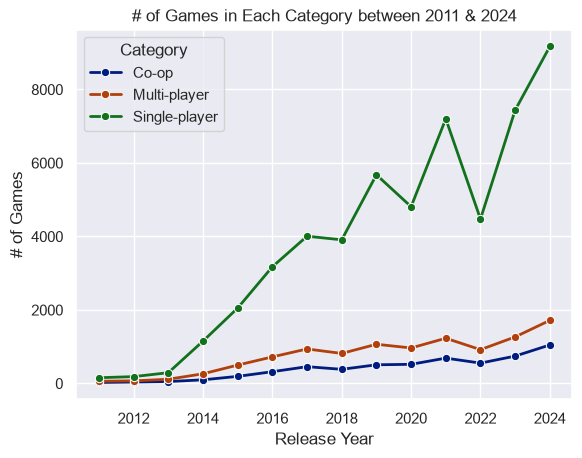

In [17]:
sns.lineplot(data=category_counts_year, x="Release Year", y="# of Games", hue="Category", linewidth=2, marker="o")
plt.title("# of Games in Each Category between 2011 & 2024")

In [18]:
df["genres"] = df["genres"].replace("[]", pd.NA)
df["genres"] = df["genres"].dropna().astype(str).str[1:-1].str.replace("'", "").str.split(", ")

genres_exploded = df.explode("genres").dropna(subset=["genres"])
genres_exploded.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD),release_year,release_month,release_day
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"[Single-player, Family Sharing]",Casual,0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"[Single-player, Family Sharing]",Indie,0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"[Single-player, Multi-player, Co-op, Online Co...",Action,0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"[Single-player, Multi-player, Co-op, Online Co...",Adventure,0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
2,2719600,Lorhaven: Cursed War,['GoldenGod Games'],['GoldenGod Games'],"[Single-player, Multi-player, PvP, Shared/Spli...",RPG,0,32,"['windows', 'mac']",True,2024-01-26,9,8,1,0.0,9 user reviews,88.9,0,False,9.99,2024,1,26


(np.float64(-0.5), np.float64(399.5), np.float64(199.5), np.float64(-0.5))

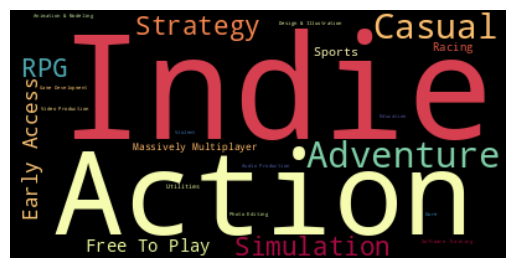

In [19]:
genres_count = genres_exploded["genres"].value_counts()

genres_cloud = WordCloud(
    background_color="black",
    colormap="Spectral",
    prefer_horizontal=0.9).generate_from_frequencies(genres_count)
plt.imshow(genres_cloud, interpolation='bilinear')
plt.axis("off")

In [20]:
platforms = df["platforms"].str[1:-1].str.replace("'", "").str.replace(" ", "").str.get_dummies(sep=",")

platforms

,linux,mac,windows
0,0,0,1
1,0,0,1
2,0,1,1
3,0,0,1
4,0,0,1
...,...,...,...
71424,0,0,1
71425,0,0,1
71426,0,0,1
71427,0,0,1


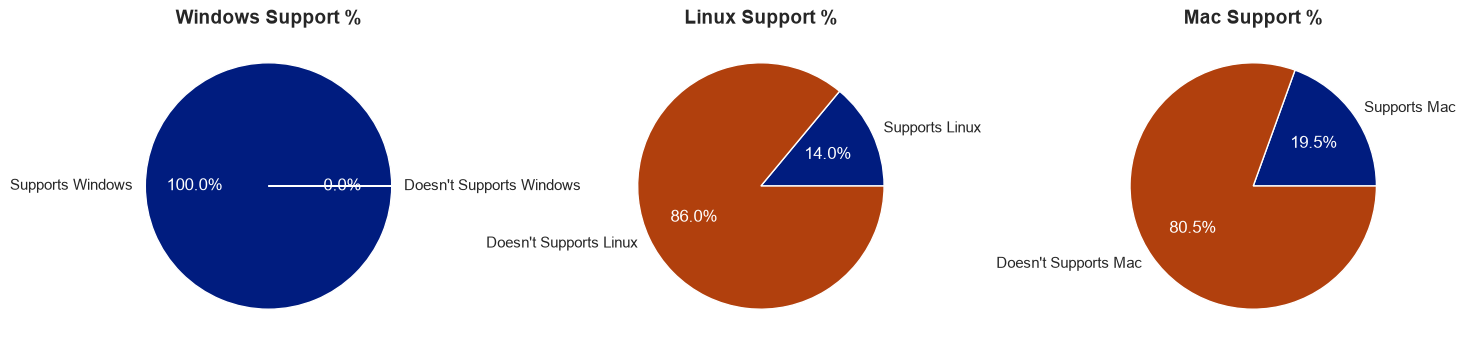

In [21]:
platform_percent = platforms.mean() * 100

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,4))


_, _, autotext = ax1.pie(
    [platform_percent["windows"], 100 - platform_percent["windows"]],
    labels=["Supports Windows", "Doesn't Supports Windows"],
    autopct="%1.1f%%"
)

ax1.set_title("Windows Support %", fontsize=14, fontweight="bold")

autotexts = [autotext]

_, _, autotext = ax2.pie(
    [platform_percent["linux"], 100 - platform_percent["linux"]],
    labels=["Supports Linux", "Doesn't Supports Linux"],
    autopct="%1.1f%%"
)

ax2.set_title("Linux Support %", fontsize=14, fontweight="bold")

autotexts.append(autotext)

_, _, autotext = ax3.pie(
    [platform_percent["mac"], 100 - platform_percent["mac"]],
    labels=["Supports Mac", "Doesn't Supports Mac"],
    autopct="%1.1f%%"
)

ax3.set_title("Mac Support %", fontsize=14, fontweight="bold")

autotexts.append(autotext)

for autotext in autotexts:
    for subautotext in autotext:
        subautotext.set_color("white")


In [22]:
df.head()

,steam_appid,name,developers,publishers,categories,genres,required_age,n_achievements,platforms,is_released,release_date,total_reviews,total_positive,total_negative,review_score,review_score_desc,positive_percentual,metacritic,is_free,price_initial (USD),release_year,release_month,release_day
0,2719580,勇者の伝説の勇者,['ぽけそう'],['ぽけそう'],"[Single-player, Family Sharing]","[Casual, Indie]",0,0,['windows'],True,2024-01-04,0,0,0,0.0,No user reviews,0.0,0,False,0.99,2024,1,4
1,2719590,Light No Fire,['Hello Games'],['Hello Games'],"[Single-player, Multi-player, Co-op, Online Co...","[Action, Adventure]",0,0,['windows'],False,NaT,0,0,0,0.0,No user reviews,0.0,0,False,0.00,<NA>,<NA>,<NA>
2,2719600,Lorhaven: Cursed War,['GoldenGod Games'],['GoldenGod Games'],"[Single-player, Multi-player, PvP, Shared/Spli...","[RPG, Strategy]",0,32,"['windows', 'mac']",True,2024-01-26,9,8,1,0.0,9 user reviews,88.9,0,False,9.99,2024,1,26
3,2719610,PUIQ: Demons,['Giammnn'],['Giammnn'],"[Single-player, Steam Achievements, Family Sha...","[Action, Casual, Indie, RPG]",0,28,['windows'],True,2024-02-17,0,0,0,0.0,No user reviews,0.0,0,False,2.99,2024,2,17
4,2719650,Project XSTING,['Saucy Melon'],['Saucy Melon'],"[Single-player, Steam Achievements, Steam Clou...","[Action, Casual, Indie, Early Access]",0,42,['windows'],True,2024-01-05,9,9,0,0.0,9 user reviews,100.0,0,False,7.99,2024,1,5


Text(0.5, 1.0, 'Average Price of a Game on Steam - 2011 to 2024')

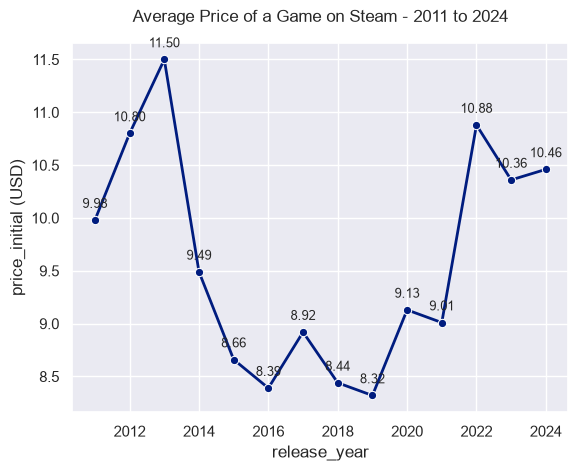

In [23]:
filter = df[(df["release_year"] > 2010) & (df["release_year"] != 2025) &
            (df["price_initial (USD)"] < 200) & (df["price_initial (USD)"] > 0)]
avg_price_year = filter.groupby("release_year")["price_initial (USD)"].mean().round(decimals=2).reset_index()

sns.lineplot(data=avg_price_year, x="release_year", y="price_initial (USD)", marker='o', linewidth=2)

ax = plt.gca()

for x, y in zip(avg_price_year["release_year"], avg_price_year["price_initial (USD)"]):
    ax.text(x, y+0.09, f"{y:.2f}", ha='center', va='bottom', fontsize=9)

plt.title("Average Price of a Game on Steam - 2011 to 2024", pad=15)